# Key steps
1.	Feature detection
2.	Feature description
3.	Feature matching

1st and 2nd steps are the most complex, further we will focus on them.
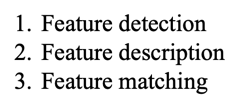
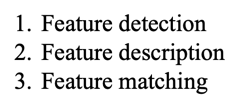

# HARRIS corner detector

1. Corners are good features. Find corners based on gradients (by X and by Y)
2. Properties:
    1.	Rotation: invariant
    2.	Scale: not invariant`
3. NMS suppression:
    1.	Take the pixel with the highest intensity within a window
    2.	Set that as the corner point and the rest to zero

<img src="key_point_recognition_images/HARRIS_corner_detection.png" width="1000">
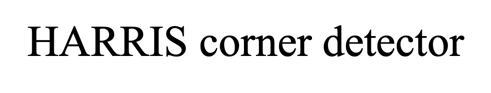
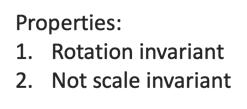

# SIFT (Patented)
## (detector + descriptor)

1. To make the algorithm scale invariant, we create a scale pyramid (_octaves_).
2. For each octave, apply a Gaussian filter with different parameters.
<img src="key_point_recognition_images/SIFT_scale.png" width="1000">

3. Calculate _Differences of Gaussians_ – differences between consecutive elements in each _octave_.
<img src="key_point_recognition_images/SIFT_DoG.png" width="1000">

4. Find local extrema
5. Filter-out low-contrast and edge response points
6. Orientation assignment:
    1. Calculate gradients and magnitude in a small region around the key-point
    2. Create an orientation histogram with 36 bins
    3. The highest peak + all peaks with magnitude >80% of the highest peak are used to assign the direction of the key-point.
<img src="key_point_recognition_images/SIFT_orientation.png" width="500">

7. Compute feature descriptor:
   1. Compute image gradients over 16*16 path around the key-point
   2. Rotate gradients and their locations relative to the key-point orientation
   3. Create 4*4 array of orientation histograms
   4. Add the rotated gradients into their local orientation histograms with 8 orientation bins
   5. The resulting SIFT descriptor is a length 128 vector representing a 4x4 histogram array with 8 orientation bins per histogram
<img src="key_point_recognition_images/SIFT_descriptor.png" width="1000">

8. Properties:
    1.	Rotation: invariant
    2.	Scale: invariant
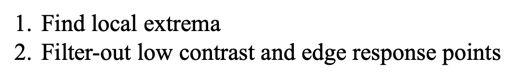

# FAST
## (detector only)

1. Select pixel p with intensity Ip
2. Select threshold t
3. Consider a circle of 16 pixels around the pixel under test.
4. P is a corner, if there is a set of 12 contiguous pixels that are all brighter than Ip + t, or all darker than Ip - t.
5. To speed up the algorithm: first check the intensity of pixels 1, 5, 9 and 13. At least three of these four pixels should satisfy the threshold criterion.
<img src="key_point_recognition_images/FAST.png" width="1000">

6. Properties:
    1.	Rotation: invariant
    2.	Scale: not invariant

# BRISK
## (detector only)

1. Open-source alternative to SIFT
2. Create an image pyramid
3. Apply FAST algorithm to each image
<img src="key_point_recognition_images/BRISK.png" width="500">

# ORB (Oriented FAST and Rotated BRIEF)
## (detector + descriptor)

1. Create an image pyramid
2. Apply FAST to each level
3. Orientation assignment:
   1. Compute moments:
<img src="key_point_recognition_images/ORB_moments.png" width="1000">
   2. Calculate centroid:
<img src="key_point_recognition_images/ORB_centroids.png" width="300">
   3. Compute the orientation angle: the angle between the vector from the keypoint center to the centroid and the horizontal axis.

4. Rotated BRIEF:
    1. Rotate key-point
    2. Select a random pair of pixels in a neighborhood around the keypoint.
    3. Draw the first pixel from a Gaussian distribution centered at key-point and std sigma.
    4. Draw the second pixel from the Gaussian distribution centered at the first pixel with std sigma / 2.
    5. Assign value 1 if first pixel is brighter to second and 0 otherwise.
    6. Repeat 128 or 512 times
    7. Pre-compute feature vectors for different key-point rotations (30)
    8. Select features with high variance, have a mean close to 0.5 and do not correlate with each other.
